# 04 · Intent classifier: fine-tuning, model selection, and distribution shift — Musta'jir

**Purpose.** Route each question (factual / calculation / procedural / out-of-scope / advice-seeking / crisis)
without an LLM call. Compares a transparent rule baseline, a **fine-tuned multilingual DistilBERT** (full vs LoRA),
and an LLM classifier - and reports the most important finding honestly: **in-distribution accuracy badly
overstated real-world accuracy**, and what fixed it.

**Runs on:** Colab (GPU optional; training takes ~45 s per seed on a T4/GTX 1650). Set `RUN_TRAINING = True` to retrain;
otherwise saved results in `data/eval/runs/` are shown.

## 1 · Setup

In [1]:
import os, sys, subprocess
from pathlib import Path
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import userdata
    if not Path("dubai-tenancy-assistant").exists():
        try:   # a read-only token is only needed if the repository is private
            auth = userdata.get("GITHUB_TOKEN") + "@"
        except Exception:
            auth = ""
        subprocess.run(["git", "clone", f"https://{auth}github.com/bettinacodes/dubai-tenancy-assistant.git"], check=True)
    os.chdir("dubai-tenancy-assistant")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", ".", "peft", "accelerate", "wordfreq"], check=True)
    sys.path.insert(0, "src")
else:
    root = Path.cwd()
    while not (root / "pyproject.toml").exists():
        root = root.parent
    os.chdir(root); sys.path.insert(0, str(root / "src"))
import json
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from tenancy_rag import config
RUNS = config.EVAL / "runs"
RUN_TRAINING = False

## 2 · The dataset
* **Round 1:** 108 hand-written seeds + 322 paraphrases from a local LLM (qwen2.5:3b) -> automatic quality gates (garbled text,
  leaked prompt instructions, lost numbers), a **manual label check** (35 rejects: e.g. *landlord* turned into *boss*,
  *should I* turned into *can I*), a **leakage filter** (any item with cosine >= 0.85 to an evaluation question removed) and
  a near-duplicate filter -> 248 items. Only **45% of LLM paraphrases survived**.
* **Round 2:** 63 more human seeds (no paraphrasing) contrasting *what the law says* ("Can I...?", "Is it allowed...?") with
  *what should I do* ("Should I...?", "Will I win?") - see §5 for why. Round-1 split assignments were kept fixed.

In [2]:
ds = pd.DataFrame([json.loads(l) for l in open(config.DATA / "intent" / "intent_dataset.jsonl", encoding="utf-8")])
rep = json.loads((config.DATA / "intent" / "build_report.json").read_text(encoding="utf-8"))
print({k: rep[k] for k in ("candidates", "dropped_quality", "dropped_leakage", "dropped_near_duplicate", "kept")})
pd.crosstab(ds.intent, [ds.split], margins=True)

{'candidates': 493, 'dropped_quality': 44, 'dropped_leakage': 25, 'dropped_near_duplicate': 117, 'kept': 307}


split,test,train,val,All
intent,,,,
advice_seeking,13,30,9,52
calculation,7,25,7,39
crisis,6,27,6,39
factual,10,51,8,69
out_of_scope,8,30,8,46
procedural,7,45,10,62
All,51,208,48,307


In [3]:
pd.crosstab(ds.intent, ds.origin, margins=True)

origin,llm_paraphrase,seed,seed_round2,All
intent,,,,
advice_seeking,26,17,9,52
calculation,18,14,7,39
crisis,20,16,3,39
factual,23,19,27,69
out_of_scope,24,18,4,46
procedural,35,18,9,62
All,146,102,59,307


## 3 · Training (full fine-tuning vs LoRA, 3 seeds each)

In [4]:
if RUN_TRAINING:
    subprocess.run([sys.executable, "-m", "tenancy_rag.understand.distilbert_clf", "train", "--seeds", "0", "1", "2"], check=True)
    subprocess.run([sys.executable, "-m", "tenancy_rag.understand.distilbert_clf", "train", "--seeds", "0", "1", "2", "--lora", "--epochs", "20"], check=True)
rows = []
for f, label in [("intent_finetune__full_round1.json", "full FT, round-1 data"), ("intent_finetune__lora.json", "LoRA r=8, round-1 data"),
                 ("intent_finetune__full.json", "full FT, round-2 data")]:
    s = json.loads((RUNS / f).read_text(encoding="utf-8"))
    for r in s["runs"]:
        rows.append({"variant": label, "seed": r["seed"], "best_epoch": r["best"]["epoch"], "val_macro_f1": round(r["best"]["val_macro_f1"], 3),
                     "test_macro_f1": r["test_macro_f1"], "trainable_params": r["trainable_params"], "train_s": r["train_seconds"]})
runs = pd.DataFrame(rows)
runs.groupby("variant")[["val_macro_f1", "test_macro_f1", "trainable_params", "train_s"]].agg(["mean", "std"]).round(3)

val_macro_f1        test_macro_f1         \
                               mean    std          mean    std   
variant                                                           
LoRA r=8, round-1 data        0.721  0.028         0.866  0.072   
full FT, round-1 data         0.687  0.033         0.920  0.017   
full FT, round-2 data         0.729  0.030         0.852  0.036   

                       trainable_params      train_s         
                                   mean  std    mean    std  
variant                                                      
LoRA r=8, round-1 data         742662.0  0.0  34.933  0.577  
full FT, round-1 data       135329286.0  0.0  41.400  2.778  
full FT, round-2 data       135329286.0  0.0  47.867  1.904

**Reading:** full fine-tuning of the 135M-parameter encoder (0.920 +/- 0.017 test macro-F1 on round-1 data, sample std over 3 seeds) beats LoRA
(0.866 +/- 0.072), which trains only 0.74M parameters (0.55%) - with ~180 examples the extra capacity helps and LoRA is
far more seed-sensitive. Note also that **val F1 (~0.7) is far below test F1 (~0.9)**: the 35-item val split is tiny and
noisy, which is why three seeds are reported and the deployed checkpoint is chosen by val, never by test.
(The round-2 test split includes 14 harder new items, so its numbers are not comparable to round 1 - §4 compares on identical sets.)

## 4 · The finding: in-distribution accuracy overstated real-world accuracy

In [5]:
cmp = json.loads((RUNS / "intent_model_comparison.json").read_text(encoding="utf-8"))
names = {"rules": "Rules (transparent baseline)", "llm_qwen2.5-3b": "LLM qwen2.5:3b (JSON prompt)",
         "distilbert_round1": "DistilBERT FT, round-1 data", "distilbert_round2": "DistilBERT FT, round-2 data",
         "hybrid_rules+distilbert@0.95": "Hybrid: rules + DistilBERT (>=0.95, add-only)"}
tab = pd.DataFrame({names[m]: {"intent F1 - paraphrase test (in-distribution, n=37)": r["intent_test_r1"]["macro_f1"],
                               "routing acc - gold dev (n=15)": r["gold_dev"]["route_acc"],
                               "routing acc - gold test (n=35)": r["gold_test"]["route_acc"],
                               "routing acc - adversarial (n=20)": r["adversarial"]["route_acc"]} for m, r in cmp.items() if m in names}).T
tab.round(2)

,"intent F1 - paraphrase test (in-distribution, n=37)",routing acc - gold dev (n=15),routing acc - gold test (n=35),routing acc - adversarial (n=20)
Rules (transparent baseline),0.81,0.93,0.97,0.95
"DistilBERT FT, round-1 data",0.91,0.33,0.66,0.80
"DistilBERT FT, round-2 data",0.91,0.87,0.94,0.80
"Hybrid: rules + DistilBERT (>=0.95, add-only)",0.84,0.93,0.97,0.95
LLM qwen2.5:3b (JSON prompt),0.83,0.60,0.57,0.80


The round-1 DistilBERT scored **0.91** on its own (paraphrase-generated) test split but routed only **33%** of the gold dev
questions correctly: real tenant questions such as *"Can I renovate my apartment myself?"* or *"Do I need my landlord's
permission to sublease?"* were classified as **advice-seeking** - which would hide a legitimate legal answer behind an
options template. The training data contained "Can I ...?" mostly in advice examples. Its confidence did not help: several
wrong predictions had probability >= 0.9 (miscalibration under shift).

**Fix (round 2):** 63 human seeds that contrast the two. Routing on gold dev rose from 0.33 to 0.87 and on gold test from
0.66 to 0.94, with in-distribution F1 unchanged. *Caveat:* the failure pattern was identified on the evaluation questions, so
post-fix numbers on them are optimistic; an unseen question set would be needed for an unbiased estimate (future work).

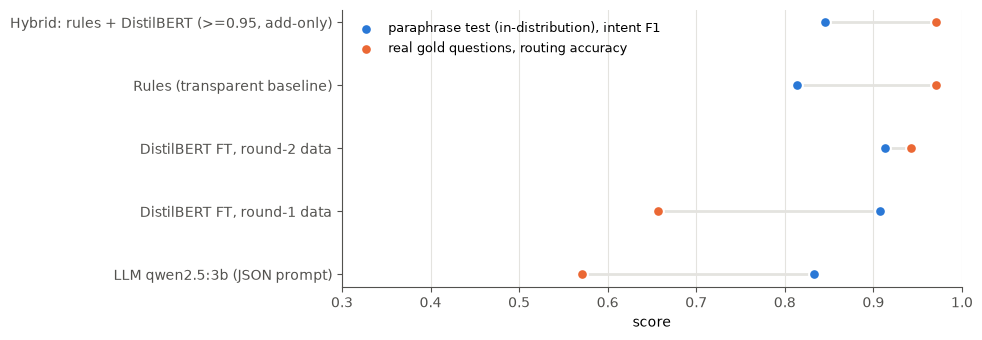

In [6]:
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "axes.axisbelow": True, "savefig.dpi": 200, "savefig.bbox": "tight"})
FIG = config.ROOT / "figures"
order = ["llm_qwen2.5-3b", "distilbert_round1", "distilbert_round2", "rules", "hybrid_rules+distilbert@0.95"]
fig, ax = plt.subplots(figsize=(8, 3.6))
for i, m in enumerate(order):
    a, b = cmp[m]["intent_test_r1"]["macro_f1"], cmp[m]["gold_test"]["route_acc"]
    ax.plot([a, b], [i, i], color=GRID, linewidth=2, zorder=1)
    ax.scatter([a], [i], s=60, color="#2a78d6", edgecolor="white", linewidth=1.5, zorder=3, label="paraphrase test (in-distribution), intent F1" if i == 0 else None)
    ax.scatter([b], [i], s=60, color="#eb6834", edgecolor="white", linewidth=1.5, zorder=3, label="real gold questions, routing accuracy" if i == 0 else None)
ax.set_yticks(range(len(order)), [names[m] for m in order]); ax.set_xlim(0.3, 1.0); ax.grid(axis="y", visible=False)
ax.set_xlabel("score"); ax.legend(frameon=False, loc="upper left", fontsize=9)
fig.savefig(FIG / "fig5_1_intent_shift.png"); plt.show()

## 5 · Deployed policy: hybrid, add-only, high threshold
Costs are asymmetric: sending a factual question to *advice* or *crisis* hides an answer, while an advice question that
reaches the generator is still caught by its advice guard. So the transparent rules decide, and the fine-tuned model may
only **add** a protective route (advice / crisis / out-of-scope) when its probability is >= 0.95. The threshold was chosen
on selection data only (gold dev: tie at 0.933 for 0.8/0.9/0.95; intent val: 0.9 = 0.95 = 0.908 > 0.8 -> the more
conservative 0.95). On held-out data the hybrid matches the rules' routing (gold test 0.97, adversarial 0.95) and raises
in-distribution intent F1 from 0.81 to 0.84. The LLM classifier is slower (~3.5 s vs ~50 ms) and worse on real questions.

**Lesson:** an encoder fine-tuned on a few hundred synthetic examples is cheap and fast, but its benchmark
score is only as good as the diversity of its training data; error analysis on realistic questions - not the in-distribution
test split - is what revealed and fixed the problem.